In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [4]:
%matplotlib inline

In [5]:
path = "./dendrites_rect_filtered.tif"
movie = tifffile.imread(path)

In [6]:
unvec = UnVectorizer(movie.shape[1:])

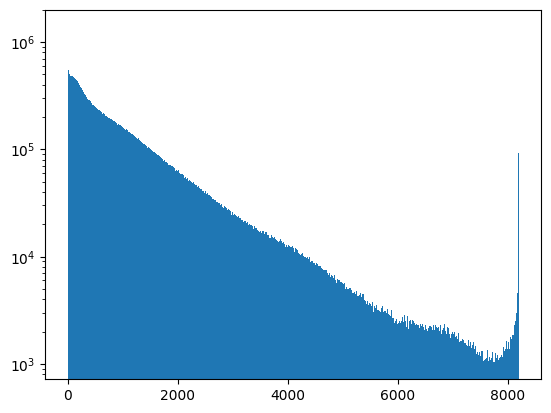

In [7]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [8]:
def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [9]:
sn, psdx = get_noise_fft(movie.transpose(1, 2, 0))

movie /= sn

In [10]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [11]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [18]:
filt_movie = Vectorizer().transform(movie)

In [19]:
iw_movie.set_data(unvec.transform(filt_movie), reset_indices=False)

In [20]:
from sklearn.preprocessing import RobustScaler

In [21]:
ss = RobustScaler()

In [22]:
Y = ss.fit_transform(filt_movie.T).T

In [23]:
iw_movie.set_data(unvec.transform(Y), reset_indices=False)

In [24]:
Y

array([[ 0.00000000e+00,  0.00000000e+00,  2.22222209e-01, ...,
         3.99259262e+01,  4.57037048e+01,  0.00000000e+00],
       [-3.04054052e-01, -3.04054052e-01, -3.04054052e-01, ...,
         1.52364855e+01,  1.46734228e+01, -3.04054052e-01],
       [-2.31850147e-01, -2.31850147e-01, -2.31850147e-01, ...,
         3.52810311e+00,  4.98711920e+00, -3.47775191e-01],
       ...,
       [ 7.98886418e-01,  7.98886418e-01,  7.98886418e-01, ...,
        -8.35174143e-01,  2.01345778e+00, -3.69884109e+00],
       [ 4.41096663e-01,  7.79933870e-01,  8.74661803e-01, ...,
        -7.36867309e-01, -8.15855265e-01, -3.18279171e+00],
       [ 8.94749820e-01,  8.94749820e-01,  7.72992313e-01, ...,
         1.07608289e-01,  2.25889999e-02, -2.42708206e+00]], dtype=float32)

In [25]:
Y.shape

(2915, 19999)

In [26]:
ixs = np.where(np.apply_along_axis(lambda Y_p: np.count_nonzero(Y_p > 3.0) > 10, axis=1, arr=Y))[0]

In [27]:
Y = Y[ixs]

In [28]:
unvec.pixel_indices = ixs

In [29]:
Y.shape

(2828, 19999)

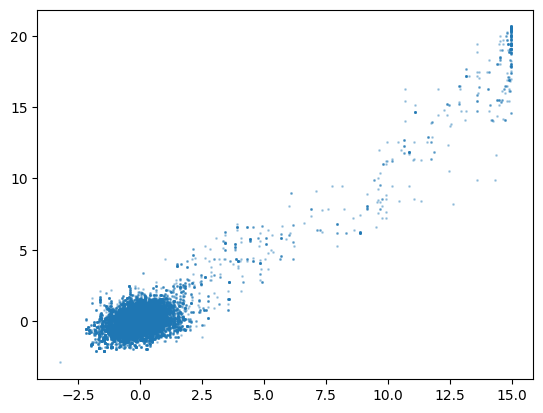

In [91]:
i = 1185
j = 1186

u = Y[i]
v = Y[j]

X = np.column_stack([u, v])

plt.scatter(u, v, s=1, alpha=.3)

In [32]:
from scipy.sparse.linalg import eigsh, svds

In [28]:
%%time
evals, evecs = eigsh(XX_T, k=1)

CPU times: user 7.02 ms, sys: 0 ns, total: 7.02 ms
Wall time: 6.59 ms


In [29]:
%%timeit
U, S, Vt = np.linalg.svd(X, full_matrices=False)

29.6 μs ± 996 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [92]:
XTX = X.T @ X

In [93]:
XTX.shape

(2, 2)

In [94]:
from scipy.linalg import eigh

In [95]:
evals, evecs = np.linalg.eigh(XTX)
evals, evecs

(array([  8333.785, 221373.14 ], dtype=float32),
 array([[-0.7726534,  0.6348281],
        [ 0.6348281,  0.7726534]], dtype=float32))

In [96]:
U, S, Vt = np.linalg.svd(X, full_matrices=False)

In [97]:
Vt.shape

(2, 2)

In [98]:
Vt

array([[ 0.63482803,  0.77265346],
       [ 0.77265346, -0.63482803]], dtype=float32)

In [99]:
Vt[0]

array([0.63482803, 0.77265346], dtype=float32)

In [100]:
evecs[0]

array([-0.7726534,  0.6348281], dtype=float32)

In [138]:
projections = (X @ Vt[0, :])[:, None] * Vt[0, :]

In [139]:
projections

array([[-1.2926277 , -1.5732658 ],
       [-1.3083256 , -1.592372  ],
       [-1.3083256 , -1.592372  ],
       ...,
       [-0.43607813, -0.5307536 ],
       [ 0.19649202,  0.23915175],
       [-2.7242038 , -3.3156466 ]], dtype=float32)

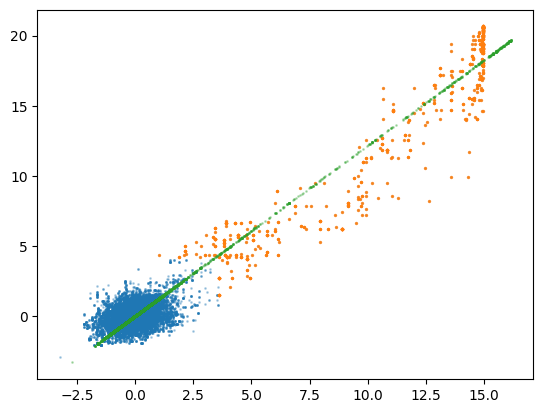

In [144]:
plt.scatter(u, v, s=1, alpha=.3)
high_val_ixs = (u > np.percentile(u, 97)) | (v > np.percentile(v, 97))
plt.scatter(u[high_val_ixs], v[high_val_ixs], s=2, alpha=0.8)
plt.scatter(projections[:, 0], projections[:, 1], s=1, alpha=0.3)

In [142]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [155]:
@njit(parallel=True)
def get_distances(
    i: int, 
    Y: np.ndarray, 
    # ysum: np.ndarray, 
    projections: np.ndarray,
    dist_reg: np.ndarray,
    # dist_h: np.ndarray,
    # dist_v: np.ndarray,
):
    if i > Y.shape[0] - 1:
        raise IndexError(f"index {i} is out of bounds for axis 0 with size {Y.shape[0]}")
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]
        
        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]
        
        i_dot_j = np.dot(u, v)
        i_dot_i = np.dot(u, u)
        
        m = (i_dot_j - 1 / high_val_ixs.sum() * u.sum() * v.sum()) / (i_dot_i - 1 / high_val_ixs.sum() * u.sum()**2)
        # m = (i_dot_j - 1 / Y.shape[1] * ysum[i] * ysum[j]) / (i_dot_i - 1 / Y.shape[1] * ysum[i]**2)
        
        v1 = np.array([m, 1])

        # Step 1: Calculate means of x and y
        u_mean = np.mean(u)
        v_mean = np.mean(v)
        
        v1[0] += u_mean
        v1[1] += v_mean

        denom = np.sqrt(v1.sum())
        v1[0] = v1[0] / denom
        v1[1] = v1[1] / denom

        v1 /= np.sqrt(np.sum(v1**2))
        
        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v
        
        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = np.abs(X - projections[j, :u.size])  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
        # orthogonal_distances = orthogonal_distances**2
        
        # # # Sum of orthogonal distances
        # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000

        dist_reg[j] = s**2

        # h = np.array([1, 0])
        # s = np.column_stack([u, v])
        # projections = (s @ h)[:, None] * h

In [156]:
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))

In [157]:
projections.shape

(2828, 19999, 2)

In [158]:
%%time
get_distances(
    1320,
    Y,
    projections,
    output_matrix,
)

CPU times: user 16.1 s, sys: 219 ms, total: 16.3 s
Wall time: 14.1 s


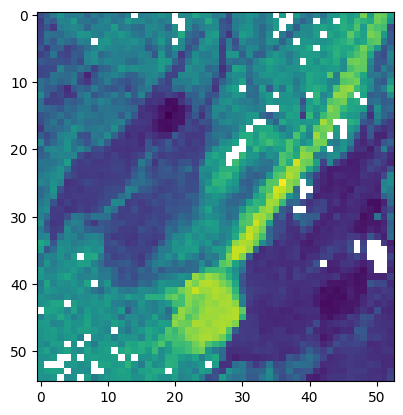

In [159]:
plt.imshow(unvec.transform(output_matrix), cmap="viridis_r")

In [160]:
std = unvec.transform(Y).std(axis=0)
std = np.nan_to_num(std, nan=0)

In [161]:
std

array([[2.4734147 , 0.9972673 , 0.8320099 , ..., 0.81757504, 1.0947676 ,
        0.93233997],
       [2.0900373 , 0.93682855, 0.9972156 , ..., 0.8952764 , 1.0465058 ,
        0.8714665 ],
       [1.6539087 , 1.2306794 , 1.4415797 , ..., 1.2179061 , 0.885389  ,
        1.2092069 ],
       ...,
       [0.7314872 , 0.        , 0.        , ..., 1.8637861 , 1.595419  ,
        1.3325665 ],
       [0.75109285, 0.7021695 , 0.7500895 , ..., 1.6210614 , 1.4696833 ,
        1.2017977 ],
       [0.7209403 , 0.75514036, 0.7536435 , ..., 1.7030708 , 1.4163556 ,
        1.0688996 ]], dtype=float32)

In [162]:
np.where(unvec.pixel_indices == 2)[0].size

1

In [58]:
iw = fpl.ImageWidget([std, np.zeros(std.shape)], cmap="viridis")

pixel_index_A = 0
projections = np.zeros((*Y.shape, 2))

pixel_A_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="magenta")
pixel_B_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="cyan")

@iw.managed_graphics[0].add_event_handler("double_click")
def update_distance_image(ev):
    global pixel_index_A
    global projections
    
    col, row = ev.pick_info["index"]

    i = np.ravel_multi_index((row, col), unvec.shape)
    subset_indices = np.where(unvec.pixel_indices == i)[0]
    if subset_indices.size < 1:
        return
        
    pixel_index_A = subset_indices.item()

    pixel_A_pt.data[0, 0] = col
    pixel_A_pt.data[0, 1] = row
    
    output_matrix = np.zeros((Y.shape[0],))
    projections = np.zeros((*Y.shape, 2))
    get_distances(
        pixel_index_A,
        Y,
        projections,
        output_matrix
    )

    output_matrix = np.nan_to_num(output_matrix, nan=np.nanmax(output_matrix))
    np.nan_to_num(output_matrix, nan=np.nanmax(output_matrix))
    iw.managed_graphics[1].data = unvec.transform(output_matrix)
    iw.reset_vmin_vmax()


fig_s = fpl.Figure(shape=(1, 2))

scatter_corr = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors=(1, 0.7, 0, 0.3), alpha=0.3)
scatter_proj = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors="r", alpha=0.3)
fig_s[0, 0].axes.colors = ("magenta", "cyan", "w")

line_p1 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="magenta", alpha=0.3)
line_p2 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="cyan", alpha=0.3)

selector_time = line_p1.add_linear_selector()

@iw.managed_graphics[1].add_event_handler("double_click")
def update_scatters(ev):
    u = Y[pixel_index_A]

    col, row = ev.pick_info["index"]

    j = np.ravel_multi_index((row, col), unvec.shape)

    subset_indices = np.where(unvec.pixel_indices == j)[0]
    if subset_indices.size < 1:
        return

    j = subset_indices.item()
    
    v = Y[j]

    pixel_B_pt.data[0, 0] = col
    pixel_B_pt.data[0, 1] = row
    
    scatter_corr.data[:, :-1] = np.column_stack([u, v])
    scatter_proj.data[:, :-1] = projections[j]
    fig_s[0, 0].auto_scale(maintain_aspect=False)

    line_p1.data[:, 1] = u
    line_p2.data[:, 1] = v
    fig_s[0, 1].auto_scale(maintain_aspect=False)

@selector_time.add_event_handler("selection")
def update_selected_time(ev):
    t = ev.get_selected_index()
    scatter_corr.colors = (1, 0.7, 0, 0.3)
    scatter_corr.sizes = 4
    v
    scatter_corr.colors[t] = "w"
    scatter_corr.sizes[t] = 20


iw.cmap = ["viridis", "viridis_r"]

VBox([iw.show(), fig_s.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [165]:
from numba import guvectorize, float64, int64, float32, prange, njit

In [166]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [226]:
for i in tqdm(range(Y.shape[0])):
    projections = np.zeros((*Y.shape, 2))
    output_matrix = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        projections,
        output_matrix,
    )
    dist_cov[i] = output_matrix

100%|███████████████████████████████████████████████████████████████████████████████████| 2828/2828 [06:27<00:00,  7.29it/s]


In [227]:
dist_cov

array([[9.3450971e-09, 5.0346468e+07, 3.6079608e+07, ..., 1.0177299e+08,
        7.8183008e+07, 4.9676724e+07],
       [1.5442042e+07, 2.5292305e-08, 1.6418589e+07, ..., 1.7379242e+07,
        1.8951888e+07, 1.9081760e+07],
       [1.7360860e+07, 1.1163748e+07, 4.5218112e-08, ..., 1.0695330e+07,
        1.0556986e+07, 1.1323614e+07],
       ...,
       [7.5087448e+07, 4.4199968e+07, 3.1066136e+07, ..., 2.9450728e-08,
        2.0303018e+06, 1.5569732e+07],
       [4.3665748e+07, 3.4972220e+07, 2.6327256e+07, ..., 2.0116889e+06,
        1.2280431e-10, 6.5018030e+06],
       [1.6929518e+07, 2.0289390e+07, 1.7675648e+07, ..., 1.2801983e+07,
        7.7777435e+06, 1.2298140e-08]], dtype=float32)

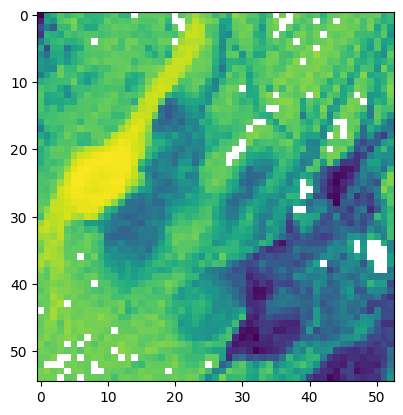

In [228]:
plt.imshow(unvec.transform(dist_cov[1185]), cmap="viridis_r")
plt.show()

In [229]:
dist_cov.min(), dist_cov.max()

(np.float32(2.9206007e-25), np.float32(174056450.0))

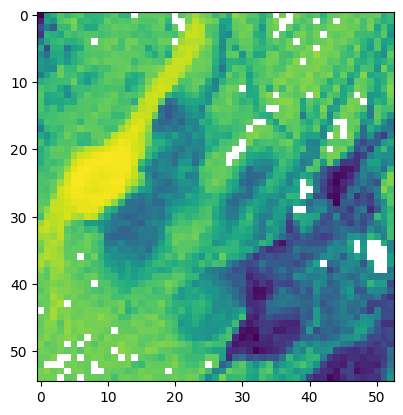

In [230]:
affinity = dist_cov.copy()
affinity -= affinity.max()
affinity = np.abs(affinity)

plt.imshow(unvec.transform(affinity[1185]))
plt.show()

In [231]:
affinity.min(), affinity.max()

(np.float32(0.0), np.float32(174056450.0))

In [232]:
from sklearn.cluster import SpectralClustering

In [272]:
n_clusters = 15
sc = SpectralClustering(n_clusters=n_clusters, affinity="precomputed")

In [273]:
labels = sc.fit_predict(affinity)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)


In [274]:
labels.shape

(2828,)

In [275]:
labels

array([12,  0,  0, ...,  7,  7,  0], dtype=int32)

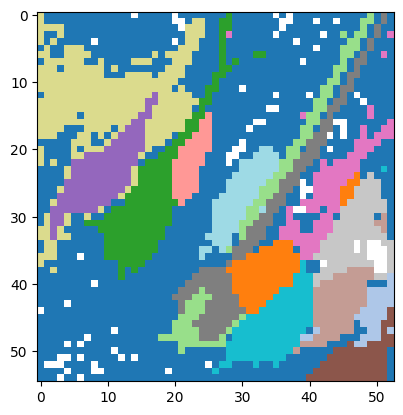

In [276]:
plt.imshow(unvec.transform(labels.astype(np.float32)), cmap="tab20")
plt.show()

In [277]:
labels

array([12,  0,  0, ...,  7,  7,  0], dtype=int32)

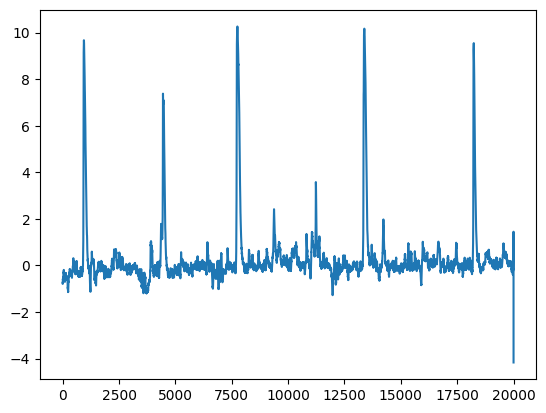

In [278]:
plt.plot(Y[labels == 2].mean(axis=0))

In [279]:
soft_labels = np.zeros((Y.shape[0], n_clusters))
soft_labels.shape

(2828, 15)

In [280]:
for n in tqdm(range(n_clusters)):
    centroid = Y[labels == n].mean(axis=0)

    # compare every pixel to this centroid
    for i in range(Y.shape[0]):
        u = centroid
        v = Y[i]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        projections = (X @ v1)[:, None] * v1

        orthogonal_distances = np.abs(X - projections)  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        soft_labels[i, n] = s

100%|███████████████████████████████████████████████████████████████████████████████████████| 15/15 [01:20<00:00,  5.34s/it]


In [281]:
soft_labels.min(), soft_labels.max()

(np.float64(518.475620626801), np.float64(9964.014271082739))

In [282]:
soft_labels -= soft_labels.max()
soft_labels = np.abs(soft_labels)

In [283]:
unvec.transform(soft_labels).shape

(15, 55, 53)

In [284]:
iw_soft = fpl.ImageWidget([l for l in unvec.transform(soft_labels)], names=[str(i) for i in range(n_clusters)], cmap="viridis", histogram_widget=False)
iw_soft.show()

RFBOutputContext()

Draw error: Validation Error (5)


JupyterWgpuCanvas()

Draw error: Validation Error (6)


In [288]:
for g in iw_soft.managed_graphics:
    g.vmin = np.nanpercentile(g.data[:], 60)